<a href="https://colab.research.google.com/github/UnitForDataScience/How_Machines_Understand_Text/blob/main/Colab-Notebooks/How_Machines_Understand_Text_NLP_Foundations_UDS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# How Machines Understand Text: Foundations of Natural Language Processing
*An Open Lab by the Unit for Data Science and Analytics at ASU Library*

---

In this notebook you will play around with NLP using real-world texts: three classic Gothic novels (*Frankenstein*, *Dracula*, and *The Picture of Dorian Gray*) and several decades of presidential State of the Union speeches. We use the Natural Language Toolkit (NLTK) and scikit-learn, two popular Python libraries. We have kept the code at a beginner level (that's all you need!) and added comments throughout so you can follow what every line does.

**This notebook is divided into the following sections:**

1. Load and prepare our texts (Part 1)
2. Turn text into tokens and numbers (Part 2)
3. Use sentiment analysis to follow emotion through a story (Part 3)
4. Use topic modeling to discover themes in State of the Union speeches (Part 4)
5. Train a classifier to guess which novel a passage comes from (Part 5, our take-home exercise)

**How this notebook is organized:**

* Run the cells from top to bottom: click a cell and press **Shift + Enter** (or use **Runtime > Run all**). Later cells depend on earlier ones, so run the whole notebook in order.
* Each Part starts with a cell that loads the libraries it needs.
* **Your turn** cells invite you to change something and see what happens. Experimenting is the best way to learn.

**Before you start:**

1. **Sign In:** Make sure you are signed in to your ASU or personal Google account (check the top-right corner).
2. **Go to File:** In the top-left menu bar, click on File.
3. **Save a Copy:** Select *Save a copy in Drive* from the dropdown menu.
4. **Work on Your Copy:** A new tab will open with a file named "Copy of [Notebook Name]". You can now rename it and your changes will be saved automatically to your own Drive.

Your copy will automatically be saved in a folder in your Google Drive called "Colab Notebooks" (Google Drive creates this folder automatically for you)

## General Libraries
Libraries are free-to-use collections of code that give Python extra abilities. We load the general-purpose libraries here, and each Part will load its own specialized tools when we get there. The comments in each cell (in green) give you an idea of what each library brings to our code.

In [1]:
import pandas as pd                 # Helps you work with data in Tables form (DataFrames)
import numpy as np                  # Fast math on lists of numbers
import re                           # "Regular expressions": find and replace patterns in text (like punctuation). Built into Python
import requests                     # Downloads files from the web. We use it to fetch our novels from Project Gutenberg
import matplotlib.pyplot as plt     # Draws charts and graphs
import warnings                     # Controls Python's warning messages
warnings.filterwarnings("ignore")   # Hide warnings to keep our output tidy

# A "seed" makes random steps repeatable, so everyone gets the same results
RANDOM_STATE = 42

print("✓ General libraries imported successfully!")

✓ General libraries imported successfully!


# Part 1: Loading our Novels
For the first parts of this notebook we will use three classic Gothic novels from [Project Gutenberg](https://www.gutenberg.org), a free library of ebooks whose copyright has expired. Each book is available as a plain text file at its own URL.

Project Gutenberg adds a license notice before and after the story. This info is not relevant to our analysis, so our function below cuts out everything outside the two `***` marker lines.


In [2]:
# The web addresses (URLs) of our three novels on Project Gutenberg
novel_urls = {
    "Frankenstein": "https://www.gutenberg.org/cache/epub/84/pg84.txt",
    "Dracula": "https://www.gutenberg.org/cache/epub/345/pg345.txt",
    "Dorian Gray": "https://www.gutenberg.org/cache/epub/174/pg174.txt",
}

# A function that downloads one book and removes the Project Gutenberg header and footer
def load_book(url):
    # Download the file
    response = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
    response.raise_for_status()   # Stop with a clear error message if the download failed

    # Turn the downloaded bytes into text
    text = response.content.decode("utf-8-sig").replace("\r\n", "\n")

    # Find where the book starts and ends (Gutenberg marks both with "***" lines)
    start = text.find("*** START OF")
    end = text.find("*** END OF")

    # Keep only the text between the markers (if a marker is missing, keep everything)
    if start != -1:
        start = text.find("\n", start) + 1   # Move to the line after the START marker
    else:
        start = 0
    if end == -1:
        end = len(text)

    return text[start:end].strip()

# Download all three books and store them in a dictionary: title -> text
books = {}
for title, url in novel_urls.items():
    books[title] = load_book(url)
    print(f"✓ Loaded {title}")

✓ Loaded Frankenstein
✓ Loaded Dracula
✓ Loaded Dorian Gray


## 1.B A Bit of Exploration
To a computer, a whole novel is just one very long **string** (a sequence of characters). In NLP, each text we analyze is called a **document**, and a collection of documents is called a **corpus**. Right now, our corpus has three documents.

**Try later:** Change `[:400]` to `[5000:5400]` (or any other numbers) and run the cell again to read a different part of the book. You can also swap `"Frankenstein"` for `"Dracula"` or `"Dorian Gray"`.

In [3]:
# How long is each book?
for title, text in books.items():
    n_words = len(text.split())   # .split() cuts the text at every space, giving us a rough word count
    print(f"{title}: {len(text):,} characters, about {n_words:,} words")

# Read the first 400 characters of Frankenstein
print("\nThe opening of Frankenstein:\n")
print(books["Frankenstein"][:400])

Frankenstein: 419,336 characters, about 75,042 words
Dracula: 845,889 characters, about 161,321 words
Dorian Gray: 429,312 characters, about 78,979 words

The opening of Frankenstein:

Frankenstein;

or, the Modern Prometheus

by Mary Wollstonecraft (Godwin) Shelley


 CONTENTS

 Letter 1
 Letter 2
 Letter 3
 Letter 4
 Chapter 1
 Chapter 2
 Chapter 3
 Chapter 4
 Chapter 5
 Chapter 6
 Chapter 7
 Chapter 8
 Chapter 9
 Chapter 10
 Chapter 11
 Chapter 12
 Chapter 13
 Chapter 14
 Chapter 15
 Chapter 16
 Chapter 17
 Chapter 18
 Chapter 19
 Chapter 20
 Chapter 21
 Chapter 22
 Chapter 2


# Part 2: From Text to Numbers
Before a computer can analyze text, it has to break it into pieces it can work with, the famous **tokens** we discussed, which can be a word or a punctuation mark.

We saw the cleaning steps in our presentation (lowercase, remove punctuation, remove stop words). Now let's apply them to real books, and then turn the tokens into numbers.

## 2.A Loading Libraries for this Part
First, let's add some more capabilites to our notebook with some new libraries.

In [4]:
# Natural Language Toolkit (NLTK)
import nltk
from nltk.tokenize import word_tokenize    # Splits text into words (tokens)
from nltk.corpus import stopwords          # A ready-made list of very common words (the, is, and...)

# scikit-learn: a popular machine learning library
from sklearn.feature_extraction.text import TfidfVectorizer   # Turns text into numbers (TF-IDF)

# Download the word lists NLTK needs (only needed the first time)
nltk.download("punkt", quiet=True)          # Rules for splitting text into words
nltk.download("punkt_tab", quiet=True)      # The newer version of the same rules
nltk.download("stopwords", quiet=True)      # The list of stop words

stop_words = set(stopwords.words("english"))   # A "set" is a collection that is very fast to search
print(f"✓ Libraries loaded. NLTK's English stop word list has {len(stop_words)} words, such as: {sorted(stop_words)[:8]}")

✓ Libraries loaded. NLTK's English stop word list has 198 words, such as: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all']


## 2.B Cleaning our Text
We wrap the cleaning steps into one function that we can reuse on any text:

1. Remove text inside square brackets (like "[Illustration]"), which is often a note and not part of the story.
2. **Lowercase** everything, so "GREAT" and "great" count as the same word.
3. **Remove punctuation** and numbers, keeping only letters and spaces.
4. **Tokenize**: split the text into words.
5. **Remove stop words** (and very short words), because words like "the" or "was" carry little meaning on their own.

Let's define the function and try it on a real passage.

In [5]:
def preprocess_text(text):
    # Remove text within brackets (often notes like [Illustration], not part of the story)
    text = re.sub(r"\[.*?\]", "", text)

    # Convert to lowercase
    text = text.lower()

    # Keep only letters and spaces
    text = re.sub(r"[^a-z\s]", "", text)

    # Tokenize (split into words)
    tokens = word_tokenize(text)

    # Remove stop words and very short words (like "ab")
    tokens = [word for word in tokens if word not in stop_words and len(word) > 2]

    return tokens

# Try it on a short passage from Frankenstein
passage = books["Frankenstein"][1000:1500]
cleaned_tokens = preprocess_text(passage)

print("BEFORE (original passage):\n", passage)
print("\nAFTER (preprocessed tokens):\n", cleaned_tokens)
print(f"\n{len(passage.split())} words before  ->  {len(cleaned_tokens)} tokens after")

BEFORE (original passage):
  breeze, which has travelled from the regions towards
which I am advancing, gives me a foretaste of those icy climes.
Inspirited by this wind of promise, my daydreams become more fervent
and vivid. I try in vain to be persuaded that the pole is the seat of
frost and desolation; it ever presents itself to my imagination as the
region of beauty and delight. There, Margaret, the sun is for ever
visible, its broad disk just skirting the horizon and diffusing a
perpetual splendour. There—for with you

AFTER (preprocessed tokens):
 ['breeze', 'travelled', 'regions', 'towards', 'advancing', 'gives', 'foretaste', 'icy', 'climes', 'inspirited', 'wind', 'promise', 'daydreams', 'become', 'fervent', 'vivid', 'try', 'vain', 'persuaded', 'pole', 'seat', 'frost', 'desolation', 'ever', 'presents', 'imagination', 'region', 'beauty', 'delight', 'margaret', 'sun', 'ever', 'visible', 'broad', 'disk', 'skirting', 'horizon', 'diffusing', 'perpetual', 'splendour', 'therefor']

87 

Now let's preprocess all three novels. Cleaning three long books takes a moment, so this cell may take a minute to run.

In [6]:
novel_tokens = {}
for title, text in books.items():
    novel_tokens[title] = preprocess_text(text)
    print(f"✓ {title}: {len(novel_tokens[title]):,} tokens after preprocessing")

✓ Frankenstein: 34,326 tokens after preprocessing
✓ Dracula: 70,082 tokens after preprocessing
✓ Dorian Gray: 36,675 tokens after preprocessing


## 2.C Which Words Matter Most? (TF-IDF)
Now we turn tokens into numbers. The simplest idea, a **bag of words**, counts how often each word appears in each text. But counting treats every word as equally important, and a word that appears in every book tells us nothing about what makes one book different from another.

**TF-IDF** (term frequency - inverse document frequency) fixes this by giving more weight to words that are *distinctive* and less weight to words that show up everywhere. Think of it as asking: "Which words make this book different from the others?" Here we treat each whole novel as one document.

After running the cell, take a close look at the top words. What kinds of words do you see? Distinctive words can often be the names of characters and places, because they appear a lot in one book and almost never in the others.

In [7]:
# TF-IDF expects text, so we join each list of tokens back into one string
novel_texts = [" ".join(tokens) for tokens in novel_tokens.values()]

novel_vectorizer = TfidfVectorizer()
novel_tfidf = novel_vectorizer.fit_transform(novel_texts)    # Learn the vocabulary and compute the weights
vocabulary = novel_vectorizer.get_feature_names_out()

print(f"Each novel is now a row of {len(vocabulary):,} numbers (one per unique word)\n")

# Show the 10 words with the highest TF-IDF score for each book
for i, title in enumerate(novel_tokens.keys()):
    scores = pd.Series(novel_tfidf[i].toarray()[0], index=vocabulary)
    top_words = scores.sort_values(ascending=False).head(10).index
    print(f"{title}: {', '.join(top_words)}")

Each novel is now a row of 16,355 numbers (one per unique word)

Frankenstein: one, could, would, yet, man, upon, life, father, elizabeth, every
Dracula: said, van, helsing, could, one, must, would, shall, may, see
Dorian Gray: dorian, one, dont, gray, would, harry, henry, said, basil, lord


# Part 3: Sentiment Analysis
Sentiment analysis tries to measure how positive or negative a piece of text is. We will use **VADER** (Valence Aware Dictionary and sEntiment Reasoner), a tool that comes with NLTK. VADER works in two steps:

1. It looks up each word in a **dictionary** (also called a **lexicon**) where every word already has a sentiment score.
2. It applies **rules** that adjust the scores, for example for negation ("not great"), intensity ("very great"), capital letters, and exclamation marks.

Notice that, unlike in Part 2, we will **not** clean the text first. VADER needs the capital letters, the punctuation, and words like "not" that we were removing before!

## 3.A Loading Libraries for this Part
First, let's add some more capabilites to our notebook with some new libraries.

In [8]:
from nltk.tokenize import sent_tokenize                       # Splits text into sentences
from nltk.sentiment.vader import SentimentIntensityAnalyzer   # VADER: scores how positive or negative a text is
from scipy.fft import dct, idct                               # The Discrete Cosine Transform, used to smooth our charts

nltk.download("vader_lexicon", quiet=True)   # VADER's dictionary of words and sentiment scores

sia = SentimentIntensityAnalyzer()    # Create our sentiment analyzer
print("✓ Libraries loaded and VADER is ready")

✓ Libraries loaded and VADER is ready


## 3.B Scoring Sentences with VADER
Let's try VADER on a few sentences, including some tricky ones. VADER gives us four numbers for each sentence:

* **neg**, **neu**, **pos**: the share of the sentence that is negative, neutral, and positive.
* **compound**: one combined score from -1 (most negative) to +1 (most positive).

A common rule of thumb is that a compound score of 0.05 or higher is positive, -0.05 or lower is negative, and anything in between is neutral.

**After running:** Compare "great" with "not great" and with "GREAT!!!". Now look at "Oh great, another delay." and "That concert was sick!". Did VADER get them right? Sarcasm, slang, and words that change meaning depending on context are where dictionary-based tools struggle.



In [9]:
test_sentences = [
    "The movie was great.",
    "The movie was not so great.",
    "The movie was GREAT!!!",
    "The movie was okay.",
    "Oh great, another delay.",
    "That concert was sick!",
]

rows = []
for sentence in test_sentences:
    scores = sia.polarity_scores(sentence)    # Returns four scores: neg, neu, pos, and compound
    scores["sentence"] = sentence
    rows.append(scores)

sentiment_table = pd.DataFrame(rows)[["sentence", "neg", "neu", "pos", "compound"]]
sentiment_table

,sentence,neg,neu,pos,compound
0,The movie was great.,0.000,0.423,0.577,0.6249
1,The movie was not so great.,0.453,0.547,0.000,-0.6296
2,The movie was GREAT!!!,0.000,0.344,0.656,0.7723
3,The movie was okay.,0.000,0.612,0.388,0.2263
4,"Oh great, another delay.",0.274,0.238,0.488,0.4215
5,That concert was sick!,0.545,0.455,0.000,-0.5562


## 3.C Peeking inside the Dictionary
Let's look at VADER's dictionary. Not every word is in it, so we use `.get()` to avoid an error when a word is missing.

In [10]:
print(f"VADER's dictionary has {len(sia.lexicon):,} words\n")

for word in ["great", "terrible", "love", "horror", "death", "monster", "vampire"]:
    print(f"{word:10s} -> {sia.lexicon.get(word, 'not in the dictionary')}")

VADER's dictionary has 7,502 words

great      -> 3.1
terrible   -> -2.1
love       -> 3.2
horror     -> -2.7
death      -> -2.9
monster    -> not in the dictionary
vampire    -> not in the dictionary


Now let's use the dictionary on a whole book. Which words in *Frankenstein* does VADER consider positive, and which negative? We will use the cleaned tokens from Part 2, and show how many times they come up in the text.

In [11]:
tokens = novel_tokens["Frankenstein"]

positive_words = [word for word in tokens if sia.lexicon.get(word, 0) > 0]
negative_words = [word for word in tokens if sia.lexicon.get(word, 0) < 0]

print("Most common positive words:")
print(pd.Series(positive_words).value_counts().head(10).to_dict())

print("\nMost common negative words:")
print(pd.Series(negative_words).value_counts().head(10).to_dict())

Most common positive words:
{'dear': 72, 'friend': 70, 'like': 61, 'love': 59, 'friends': 54, 'hope': 50, 'great': 50, 'happiness': 49, 'happy': 46, 'well': 43}

Most common negative words:
{'death': 76, 'miserable': 65, 'misery': 54, 'despair': 49, 'poor': 44, 'alone': 44, 'horror': 44, 'fear': 40, 'lost': 33, 'strange': 32}


## 3.D The Shape of a Story
A book is not just "positive" or "negative": its emotion *moves* from beginning to end. To see that movement, we split each book into sentences and score every sentence with VADER.

Scoring thousands of sentences takes a little while, so this cell may take a minute to run.

In [12]:
sentence_lists = {}     # title -> list of sentences
sentence_scores = {}    # title -> compound score of every sentence

for title, text in books.items():
    sentences = sent_tokenize(text.replace("\n", " "))     # Split the book into sentences
    sentence_lists[title] = sentences
    sentence_scores[title] = np.array([sia.polarity_scores(s)["compound"] for s in sentences])
    print(f"✓ {title}: {len(sentences):,} sentences scored | mean sentiment: {sentence_scores[title].mean():.3f}")

✓ Frankenstein: 3,075 sentences scored | mean sentiment: 0.038
✓ Dracula: 7,379 sentences scored | mean sentiment: 0.048
✓ Dorian Gray: 5,446 sentences scored | mean sentiment: 0.048


Let's look at the raw scores for one book. Each point in the chart is one sentence.

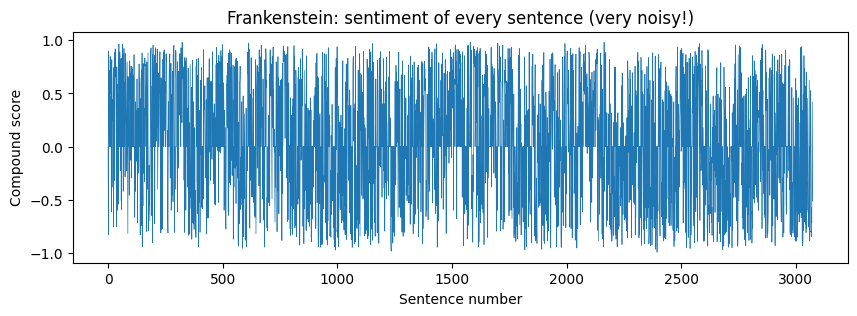

In [13]:
plt.figure(figsize=(10, 3))
plt.plot(sentence_scores["Frankenstein"], linewidth=0.5)
plt.title("Frankenstein: sentiment of every sentence (very noisy!)")
plt.xlabel("Sentence number")
plt.ylabel("Compound score")
plt.show()

That chart is full of peaks and chasms, which makes it look like noise. We want a smooth line from beginning to end that shows the overall emotional "shape" of the book. For that, we use a **Discrete Cosine Transform (DCT)**.

 A DCT breaks the noisy line into waves of different speeds. We keep only the slowest few waves and rebuild the curve from those, so we see the overall shape and not the sentence-by-sentence jitter. The function also puts every book on a common timeline from 0 to 100 (so books of different lengths can be compared) and rescales the result to the range -1 to 1.

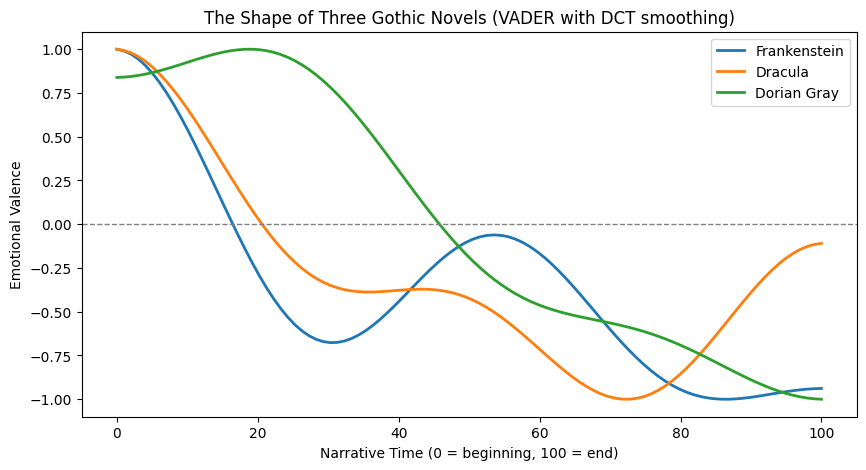

In [14]:
def dct_shape(scores, low_pass_size=5, x_reverse_len=100):
    coefficients = dct(scores, type=2, norm="ortho")          # Break the noisy signal into waves
    kept = np.zeros(x_reverse_len)
    kept[:low_pass_size] = coefficients[:low_pass_size]        # Keep only the slowest waves
    shape = idct(kept, type=2, norm="ortho")                   # Rebuild a curve with x_reverse_len points from them
    return 2 * (shape - shape.min()) / (shape.max() - shape.min()) - 1   # Scale to -1..1

LOW_PASS_SIZE = 5    # How many waves to keep (try 3, 10, or 20!)

plt.figure(figsize=(10, 5))

for title, scores in sentence_scores.items():
    shape = dct_shape(scores, low_pass_size=LOW_PASS_SIZE)
    plt.plot(np.linspace(0, 100, len(shape)), shape, linewidth=2, label=title)

plt.axhline(0, color="gray", linestyle="--", linewidth=1)    # A line at zero (neutral)
plt.xlabel("Narrative Time (0 = beginning, 100 = end)")
plt.ylabel("Emotional Valence")
plt.title("The Shape of Three Gothic Novels (VADER with DCT smoothing)")
plt.legend()
plt.show()

# Part 4: Topic Modeling with State of the Union Speeches

**Topic modeling** is a family of methods used to automatically discover themes in large collections of text. One of the most widely used approaches in both data science and the social sciences is **Latent Dirichlet Allocation (LDA)**. LDA is an *unsupervised* machine learning model, which means it needs no labels. It assumes:

* Each document is a mixture of multiple topics.
* Each topic is a collection of words that tend to show up together.

For example, a topic might contain words like *economy*, *jobs*, and *growth*, which we might interpret as an "economic policy" theme. A single speech might be 40% economy, 30% healthcare, and 30% foreign policy.

A few important things to keep in mind:

* We choose the **number of topics** ourselves.
* The model gives us numbered lists of words, and it is up to **us** to interpret them and give each topic a name.
* LDA works on word **counts** (a bag of words), so we will use `CountVectorizer`, not TF-IDF.


## 4.A Loading Libraries for this Part

In [15]:
from nltk.stem import WordNetLemmatizer                       # Reduces words to their base form (taxes -> tax)
from sklearn.feature_extraction.text import CountVectorizer   # Turns text into word counts (bag of words)
from sklearn.decomposition import LatentDirichletAllocation   # LDA: our topic modeling method

nltk.download("wordnet", quiet=True)    # A dictionary that helps us with lemmatization

lemmatizer = WordNetLemmatizer()
print("✓ Libraries loaded")

✓ Libraries loaded


## 4.B Loading the Speeches
We will use a Kaggle dataset that contains all "State of the Union" presidential speeches from 1790 to 2024. To save some time, we uploaded the dataset to GitHub. It is a .csv file with columns for the name of the president, the year the speech was given, the entire text of each speech, and the word count for the speech. That format lets us use pandas to work with the text.

In [16]:
# The web address of the dataset
url = "https://raw.githubusercontent.com/UnitForDataScience/Projects-Spring-2026/refs/heads/main/SOTU.csv"

# Load it into a pandas DataFrame
sotu_data = pd.read_csv(url)

# Display basic dataset information
print(f"Dataset shape: {sotu_data.shape}")
print(f"Column names: {list(sotu_data.columns)}")
print(f"Date range: {sotu_data['Year'].min()} - {sotu_data['Year'].max()}")
print(f"Number of speeches: {len(sotu_data)}")

sotu_data.head()

Dataset shape: (246, 4)
Column names: ['President', 'Year', 'Text', 'Word Count']
Date range: 1790.0 - 2024.0
Number of speeches: 246


,President,Year,Text,Word Count
0,Joseph R. Biden,2024.0,"\n[Before speaking, the President presented hi...",8003
1,Joseph R. Biden,2023.0,\nThe President. Mr. Speaker——\n[At this point...,8978
2,Joseph R. Biden,2022.0,"\nThe President. Thank you all very, very much...",7539
3,Joseph R. Biden,2021.0,\nThe President. Thank you. Thank you. Thank y...,7734
4,Donald J. Trump,2020.0,\nThe President. Thank you very much. Thank yo...,6169


## 4.C Choosing a Subset
For demonstration purposes (and to keep things fast), we will focus on speeches from 1945 onward. Feel free to explore other subsets. As you explore, be aware that using LDA on a very small subset might not give meaningful results.

In [17]:
START_YEAR = 1960    # Try a different year!

sotu = sotu_data[sotu_data["Year"] >= START_YEAR].reset_index(drop=True)

print(f"Full dataset: {len(sotu_data)} speeches")
print(f"Our subset ({START_YEAR} onward): {len(sotu)} speeches")

Full dataset: 246 speeches
Our subset (1960 onward): 71 speeches


## 4.D Preprocessing the Speeches
We will reuse our `preprocess_text` function from Part 2. Speeches need a few extra touches:

* We remove words that are not part of the speech itself, like "applause" and "laughter" (audience reactions that were written into the transcripts).
* We **lemmatize** the words, reducing each one to its base form, so "tax" and "taxes" count as the same word.

This cell may take a minute to run.

In [18]:
extra_stopwords = {"laughter", "applause", "inaudible", "dont", "cant"}    # Words we want to ignore

def preprocess_speech(text):
    tokens = preprocess_text(text)                                                                # Our function from Part 2
    tokens = [word for word in tokens if word not in extra_stopwords]                             # Remove the extra stop words
    tokens = [lemmatizer.lemmatize(word) for word in tokens]                                      # Reduce words to their base form
    return tokens

print("Preprocessing speeches... This may take a moment.")
sotu["tokens"] = sotu["Text"].apply(preprocess_speech)
print("✓ Preprocessing complete!")

# Compare the original text with the tokens for the first speech
first = sotu.iloc[0]
print(f"\nFirst speech: {first['Year']} - {first['President']}")
print(f"Original text (first 300 characters): {first['Text'][:300]}...")
print(f"\nTokens (first 25): {first['tokens'][:25]}")

Preprocessing speeches... This may take a moment.
✓ Preprocessing complete!

First speech: 2024.0 - Joseph R. Biden
Original text (first 300 characters): 
[Before speaking, the President presented his prepared remarks to Speaker of the House of Representatives J. Michael Johnson.]
The President. Your bedtime reading.
Tony! Thank you. Looking for Jill.
Good evening. Good evening. If I were smart, I'd go home now. [Laughter]
Mr. Speaker, Madam Vice Pre...

Tokens (first 25): ['president', 'bedtime', 'reading', 'tony', 'thank', 'looking', 'jill', 'good', 'evening', 'good', 'evening', 'smart', 'home', 'speaker', 'madam', 'vice', 'president', 'member', 'congress', 'fellow', 'american', 'january', 'franklin', 'roosevelt', 'came']


## 4.E Building a Document-Term Matrix (DTM)
A **document-term matrix** is a bag of words for the whole collection: a table where

* Rows = documents (speeches)
* Columns = unique words (terms)
* Values = how many times each word appears in each speech

Think of it as: "How many times does each word appear in each speech?"

We also filter out words that are too rare or too common, to improve the quality of our topics:

* `min_df=5` removes words that appear in fewer than 5 speeches.
* `max_df=0.8` removes words that appear in more than 80% of the speeches.

In [19]:
# CountVectorizer expects text, so we join each list of tokens back into one string
speech_texts = [" ".join(tokens) for tokens in sotu["tokens"]]

speech_vectorizer = CountVectorizer(min_df=5, max_df=0.8)
dtm = speech_vectorizer.fit_transform(speech_texts)
speech_vocabulary = speech_vectorizer.get_feature_names_out()

print(f"✓ Document-term matrix created: {dtm.shape[0]} speeches x {dtm.shape[1]} words")


✓ Document-term matrix created: 71 speeches x 3766 words


## 4.F Training our LDA Model
LDA "learns" topics by finding groups of words that frequently appear together in the same speeches. Even though it is unsupervised, we have to tell it how many topics to look for. We will start with 6.

In [20]:
NUM_TOPICS = 6    # Try 4, 8, or 10 and see what changes!

lda = LatentDirichletAllocation(n_components=NUM_TOPICS, random_state=RANDOM_STATE, max_iter=20)
lda.fit(dtm)

print(f"✓ LDA model trained with {NUM_TOPICS} topics")

✓ LDA model trained with 6 topics


## 4.G Examining the Top Words
Each topic is a list of words, and the words with the highest weights define the topic. Let's print the 10 top words for each topic.


In [21]:
for topic_id, weights in enumerate(lda.components_):
    top_ids = weights.argsort()[::-1][:10]
    print(f"Topic {topic_id}: {', '.join(speech_vocabulary[i] for i in top_ids)}")

Topic 0: administration, major, international, area, inflation, foreign, soviet, four, oil, resource
Topic 1: weve, thats, thing, thank, responsibility, parent, terrorist, put, college, hard
Topic 2: toward, look, shall, welfare, truly, crime, spirit, measure, message, decision
Topic 3: soviet, inflation, control, weve, preserve, arm, foundation, salt, value, region
Topic 4: shall, vietnam, propose, communist, local, land, seek, area, cause, among
Topic 5: thats, going, thank, look, audience, weve, folk, company, pas, ive


###Naming the Topics (Optional)
**After running:** Read each list of words and decide what each topic is about. Remember that the model does not name the topics: that is our job! Write your own names in the cell below (we have added two examples in comments), and then run it. Your names will be used in the charts that follow.

In [22]:
# Start with generic names, then replace them with your own
topic_names = {i: f"Topic {i}" for i in range(NUM_TOPICS)}

# Example (use the words you see above!):
# topic_names[0] = "Economy and jobs"
# topic_names[1] = "Foreign policy"

print(topic_names)

{0: 'Topic 0', 1: 'Topic 1', 2: 'Topic 2', 3: 'Topic 3', 4: 'Topic 4', 5: 'Topic 5'}


## 4.H Topics in each Speech
LDA treats each document as a mixture of topics, so for every speech it tells us how much of each topic it contains. Think of it as: "What is this speech mostly about?"

In [23]:
doc_topics = lda.transform(dtm)    # One row per speech, one column per topic

topic_columns = [topic_names[i] for i in range(NUM_TOPICS)]
doc_topic_table = pd.DataFrame(doc_topics, columns=topic_columns)
doc_topic_table.insert(0, "Speech", sotu["Year"].astype(str) + " - " + sotu["President"])

# Add the main topic of each speech
doc_topic_table["Main topic"] = [topic_names[i] for i in doc_topics.argmax(axis=1)]

# Show the five most recent speeches
doc_topic_table.tail().round(2)

,Speech,Topic 0,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Main topic
66,1963.0 - John F. Kennedy,0.21,0.0,0.00,0.0,0.79,0.0,Topic 4
67,1962.0 - John F. Kennedy,0.21,0.0,0.00,0.0,0.79,0.0,Topic 4
68,1961.0 - John F. Kennedy,0.17,0.0,0.08,0.0,0.75,0.0,Topic 4
69,1961.0 - Dwight D. Eisenhower,0.52,0.0,0.00,0.0,0.48,0.0,Topic 0
70,1960.0 - Dwight D. Eisenhower,0.01,0.0,0.00,0.0,0.99,0.0,Topic 4


## 4.I Topics over Time
Now for the best part: how do the themes change over the decades? We will average the topic shares for the speeches in each decade.

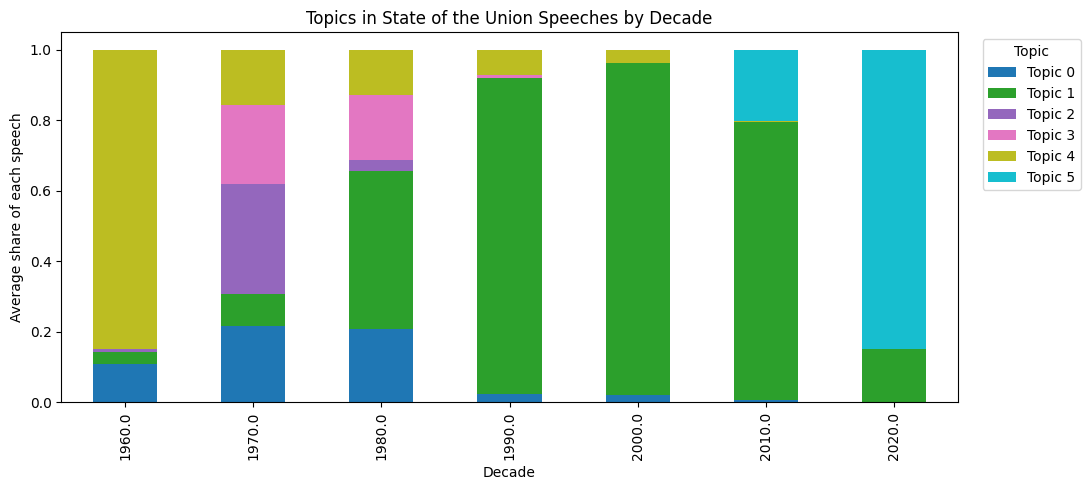

In [24]:
doc_topic_table["Decade"] = (sotu["Year"] // 10) * 10

topics_by_decade = doc_topic_table.groupby("Decade")[topic_columns].mean()

topics_by_decade.plot(kind="bar", stacked=True, figsize=(11, 5), colormap="tab10")
plt.ylabel("Average share of each speech")
plt.title("Topics in State of the Union Speeches by Decade")
plt.legend(title="Topic", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**What to notice:** Do some topics grow or fade across the decades? Does that match what you know about the history of those years?

**Your turn:** There is no single "right" number of topics. Go back to step 4.F, change `NUM_TOPICS` to 4 (or 10), and run the cells from 4.F down to here again. Do the topics split, merge, or stay the same?

# Part 5: Text Classification (Take-Home Exercise)

In Part 4, the computer discovered themes on its own. Now we will do the opposite: we will teach the computer to *answer* a question whose categories we already know: **which novel does this passage come from?**

A **classifier** is a sorting machine that learns from labeled examples. It works in three steps:

1. **Labeled examples:** we show it many passages, each already labeled with its book. This is called the *training data*.
2. **Learn patterns:** it works out which words point to which book. (With the classifier we will use, each word earns a weight for each book.)
3. **Predict a label:** for a new passage, the weights of its words add up, and the book with the strongest total wins.

Think of it as studying with flashcards. To check that the classifier has really learned something (and not just memorized the flashcards), we hold back some passages it has never seen, like an exam. The percentage it gets right is its **accuracy**.

## 5.A Libraries for this Part

In [25]:
from sklearn.model_selection import train_test_split          # Splits our data into a "practice" set and a "test" set
from sklearn.linear_model import LogisticRegression           # A simple classifier
from sklearn.pipeline import make_pipeline                    # Chains steps together (text -> numbers -> classifier)
from sklearn.metrics import ConfusionMatrixDisplay            # Shows where a classifier gets confused

print("✓ Libraries loaded")

✓ Libraries loaded


## 5.B Creating Passages
A whole novel is a single document, so we cut each book into passages of 150 words. Each passage is one example, and its book is its label. Some books are longer than others, so to keep things fair we take the same number of passages from each book.

In [26]:
PASSAGE_LENGTH = 150    # words per passage

passage_rows = []
for title, text in books.items():
    words = text.split()
    for i in range(0, len(words) - PASSAGE_LENGTH, PASSAGE_LENGTH):
        passage_rows.append({"book": title, "passage": " ".join(words[i:i + PASSAGE_LENGTH])})

passages = pd.DataFrame(passage_rows)
print("Passages per book:")
print(passages["book"].value_counts())

# Take the same number of passages from each book
n_per_book = passages["book"].value_counts().min()    # The size of our smallest book
passages = passages.groupby("book").sample(n=n_per_book, random_state=RANDOM_STATE)

print(f"\n✓ Keeping {n_per_book} passages per book")
passages.head()

Passages per book:
book
Dracula         1075
Dorian Gray      526
Frankenstein     500
Name: count, dtype: int64

✓ Keeping 500 passages per book


,book,passage
1886,Dorian Gray,forth sleep from her purple cave. Veil after v...
1972,Dorian Gray,There was a look of contempt in the steady sea...
1581,Dorian Gray,at him in amazement through the thin blue wrea...
1759,Dorian Gray,some one.” “That is certainly better than bein...
1653,Dorian Gray,"sir, a subaltern in a foot regiment, or someth..."


## 5.C Training and Test Sets
Now we hold back 25% of the passages as our "exam" (the **test set**). The classifier will only learn from the other 75% (the **training set**).

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    passages["passage"], passages["book"],
    test_size=0.25,                  # Hold back 25% of the passages for the exam
    random_state=RANDOM_STATE,
    stratify=passages["book"])       # Keep the same number of each book in both sets

print(f"Training passages: {len(X_train)}  |  Test passages: {len(X_test)}")

Training passages: 1125  |  Test passages: 375


## 5.D Training our Classifier
We chain two steps together in a **pipeline**:

1. **TF-IDF** turns each passage into numbers (Part 2).
2. **Logistic regression** learns which words point to which book.

The `fit` line is where the learning happens.

In [28]:
model = make_pipeline(
    TfidfVectorizer(stop_words="english", token_pattern=r"[A-Za-z]{3,}"),   # Step 1: text -> numbers (we keep words with 3+ letters)
    LogisticRegression(max_iter=1000))                                       # Step 2: learn which words point to which book

model.fit(X_train, y_train)    # Training happens here

accuracy = model.score(X_test, y_test)
print(f"✓ Accuracy on passages the model has never seen: {accuracy:.1%}")
print(f"  (Random guessing among {len(model.classes_)} books would get about {1 / len(model.classes_):.0%})")

✓ Accuracy on passages the model has never seen: 98.1%
  (Random guessing among 3 books would get about 33%)


## 5.E Predicting New Passages
Let's test our classifier on sentences we wrote ourselves. For each one it gives us a **probability** for every book. The last sentence has nothing to do with any of the novels. What will the classifier do?

A classifier can only choose among the labels it learned. Even for a sentence about baking a cake, it has to pick one of the three books! It does not know how to say "none of the above."


**After Running:** Write your own sentences in the list below. Can you write a sentence that fools the classifier?

In [29]:
new_passages = [
    "The creature fled across the ice, cursing the scientist who had made him.",
    "Jonathan wrote in his journal that the Count slept in a box of earth.",
    "Lord Henry lit a cigarette and smiled at the portrait.",
    "I baked a chocolate cake for the party and everyone loved it.",
]

probabilities = pd.DataFrame(model.predict_proba(new_passages).round(2), columns=model.classes_)
probabilities["prediction"] = model.predict(new_passages)
probabilities.insert(0, "passage", new_passages)
probabilities

,passage,Dorian Gray,Dracula,Frankenstein,prediction
0,"The creature fled across the ice, cursing the ...",0.16,0.15,0.69,Frankenstein
1,Jonathan wrote in his journal that the Count s...,0.08,0.75,0.17,Dracula
2,Lord Henry lit a cigarette and smiled at the p...,0.75,0.10,0.14,Dorian Gray
3,I baked a chocolate cake for the party and eve...,0.29,0.26,0.45,Frankenstein



## 5.F Peeking Inside
What did the classifier actually learn? Each word has a weight for each book, so let's see the 10 words with the biggest weights for each one.

In [30]:
tfidf_step = model.named_steps["tfidfvectorizer"]           # The first step of the pipeline
classifier_step = model.named_steps["logisticregression"]   # The second step of the pipeline
feature_names = tfidf_step.get_feature_names_out()

for i, title in enumerate(classifier_step.classes_):
    top_ids = classifier_step.coef_[i].argsort()[::-1][:10]    # The 10 words with the biggest weights for this book
    print(f"{title}: {', '.join(feature_names[j] for j in top_ids)}")

Dorian Gray: dorian, gray, don, harry, henry, lord, basil, life, sibyl, really
Dracula: lucy, van, helsing, count, jonathan, mina, shall, professor, arthur, went
Frankenstein: elizabeth, father, feelings, clerval, miserable, cottage, justine, felix, human, misery


**What to notice:** Compare these lists with the distinctive words from Part 2. The classifier found an easy shortcut: character names! That is a good reminder that a model learns whatever clues work best, not necessarily the ones we would expect or want.

## 5.G Where does it get Confused?
A **confusion matrix** shows how many passages of each book the classifier labeled correctly (the diagonal) and which books it mixed up.

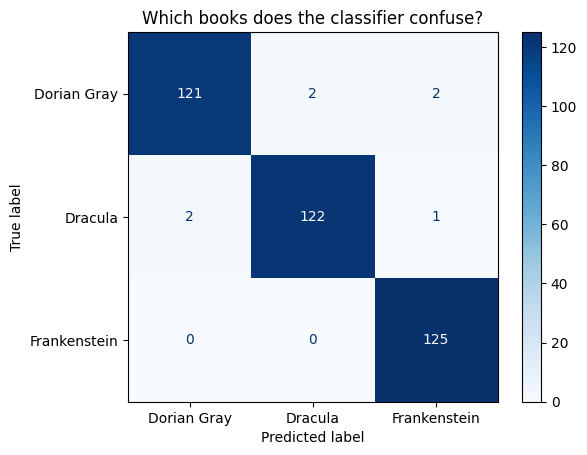

In [31]:
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap="Blues")
plt.title("Which books does the classifier confuse?")
plt.show()

**Homework challenge:** Our random split puts neighboring passages from the same chapter into both the training and test sets, which makes the exam easier than it should be. Can you build a tougher test? Train on the first 80% of each book and test on the last 20% (hint: `passage_rows` is still in the order of the books). Does the accuracy drop?

*Texts provided by Project Gutenberg (gutenberg.org). VADER: Hutto, C. J., & Gilbert, E. (2014). LDA: Blei, D. M., Ng, A. Y., & Jordan, M. I. (2003), [Latent Dirichlet Allocation](https://jmlr.org/papers/v3/blei03a.html), Journal of Machine Learning Research, 3, 993-1022.*